# Proiect A — Customer Personality Analysis

## 0. Setări

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

SEED = 42
MY_NAME = "customer"

DATA_DIR = "data"
FIGURES_DIR = "figures"
RESULTS_DIR = "results"
MODELS_DIR = "models"
for folder in [DATA_DIR, FIGURES_DIR, RESULTS_DIR, MODELS_DIR]:
    os.makedirs(folder, exist_ok=True)

TARGET_CLF = "Response"
POS_CLASS = 1
TARGET_REG = "MntTotal"
MNT_COLS = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

np.random.seed(SEED)
pd.set_option("display.max_columns", None)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.dpi"] = 100

### 0.1 Funcțiile folosite în tot notebook-ul

In [2]:
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import cross_validate

EDU_ORDER = [["Basic", "Graduation", "Master", "PhD"]]


def make_prep(num_cols, scaler=None, add_indicator=False):
    num_steps = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=add_indicator)),
                          ("scale", StandardScaler() if scaler is None else scaler)])
    ord_steps = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("ordinal", OrdinalEncoder(categories=EDU_ORDER, handle_unknown="use_encoded_value",
                                                     unknown_value=-1))])
    nom_steps = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist",
                                                   sparse_output=False))])
    return ColumnTransformer([("num", num_steps, num_cols),
                              ("ord", ord_steps, ["Education"]),
                              ("nom", nom_steps, ["Marital_Status"])])


def make_pipe(model, num_cols, scaler=None, add_indicator=False, select=None):
    steps = [("prep", make_prep(num_cols, scaler, add_indicator))]
    if select is not None:
        steps.append(("select", select))
    steps.append(("model", model))
    return Pipeline(steps)


METRICS = {
    "classification": {"PR_AUC": "average_precision", "ROC_AUC": "roc_auc", "F1": "f1", "recall": "recall",
                       "precision": "precision", "bal_acc": "balanced_accuracy"},
    "regression": {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"},
}


def evaluate(model, X, y, task, cv):
    scoring = METRICS[task]
    res = cross_validate(model, X, y, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    sign = {name: -1 if scorer.startswith("neg_") else 1 for name, scorer in scoring.items()}
    main = next(iter(scoring))
    folds = sign[main] * res[f"test_{main}"]
    row = {main: folds.mean(), f"{main}_std": folds.std(), f"{main}_train": sign[main] * res[f"train_{main}"].mean()}
    row |= {name: sign[name] * res[f"test_{name}"].mean() for name in scoring if name != main}
    row["fit_time_s"] = res["fit_time"].mean()
    return row, folds


def compare(models, X, y, task, cv):
    rows, folds = [], {}
    for name, model in models.items():
        row, folds[name] = evaluate(model, X, y, task, cv)
        rows.append({"model": name, **row})
    main = next(iter(METRICS[task]))
    table = pd.DataFrame(rows).set_index("model").sort_values(main, ascending=(task == "regression"))
    return table, folds


def corrected_ttest(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return t, p


def ttest_pair(folds, a, b, n_rows):
    k = len(folds[a])
    t, p = corrected_ttest(folds[a], folds[b], n_rows * (k - 1) / k, n_rows / k)
    verdict = "significant" if p < 0.05 else "NOT significant"
    print(f"{a} vs {b}: diff = {folds[a].mean() - folds[b].mean():+.3f}, t = {t:.2f}, p = {p:.3f} -> {verdict}")
    return p

## 1. Încărcarea datelor

In [3]:
RAW_CSV = f"{DATA_DIR}/raw.csv"
if os.path.exists(RAW_CSV):
    df_raw = pd.read_csv(RAW_CSV)
    print("Loaded from", RAW_CSV)
else:
    import kagglehub
    path = kagglehub.dataset_download("imakash3011/customer-personality-analysis")
    df_raw = pd.read_csv(f"{path}/marketing_campaign.csv", sep="\t")
    df_raw.to_csv(RAW_CSV, index=False)
    print("Downloaded from Kaggle and saved to", RAW_CSV)

print(df_raw.shape)
df_raw.head()

Loaded from data/raw.csv
(2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


## 2. Analiza exploratorie a datelor
### 2.1 Structura tabelului

In [4]:
df_raw.info()

print("\nduplicated rows:", df_raw.duplicated().sum())
print("duplicated rows without ID:", df_raw.drop(columns=["ID"]).duplicated().sum())
print("constant columns:", [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) == 1])
print("ID-like columns:", [c for c in df_raw.columns if df_raw[c].nunique() == len(df_raw)])

for c in ["Education", "Marital_Status"]:
    print(f"\n{c}:", df_raw[c].value_counts().to_dict())

print("\nsmallest Year_Birth:", df_raw["Year_Birth"].nsmallest(4).tolist())
print("largest Income:", df_raw["Income"].nlargest(3).tolist())
print("Dt_Customer dtype:", df_raw["Dt_Customer"].dtype, "| example:", df_raw["Dt_Customer"].iloc[0])

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

### 2.2 Statistici descriptive, valori lipsă, ținte

In [5]:
df_stats = df_raw.drop(columns=["ID", "Z_CostContact", "Z_Revenue"]).assign(**{TARGET_REG: df_raw[MNT_COLS].sum(axis=1)})


def numeric_summary(data):
    rows = {}
    for c in data.select_dtypes(include="number").columns:
        s = data[c]
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        rows[c] = {"missing %": 100 * s.isna().mean(), "mean": s.mean(), "median": s.median(), "std": s.std(),
                   "min": s.min(), "max": s.max(),
                   "IQR outliers": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum(), "skew": s.skew()}
    return pd.DataFrame(rows).T.round(2)


display(numeric_summary(df_stats))

missing = df_stats.isna().sum()
print("missing values:", missing[missing > 0].to_dict())

counts = df_stats[TARGET_CLF].value_counts()
print("\nclassification target:", df_stats[TARGET_CLF].value_counts(normalize=True).round(3).to_dict(),
      "| imbalance ratio:", round(counts.max() / counts.min(), 2))
print(f"regression target: mean {df_stats[TARGET_REG].mean():.0f}, median {df_stats[TARGET_REG].median():.0f}, "
      f"skew {df_stats[TARGET_REG].skew():.2f}")

,missing %,mean,median,std,min,max,IQR outliers,skew
Year_Birth,0.00,1968.81,1970.0,11.98,1893.0,1996.0,3.0,-0.35
Income,1.07,52247.25,51381.5,25173.08,1730.0,666666.0,8.0,6.76
Kidhome,0.00,0.44,0.0,0.54,0.0,2.0,0.0,0.64
Teenhome,0.00,0.51,0.0,0.54,0.0,2.0,0.0,0.41
Recency,0.00,49.11,49.0,28.96,0.0,99.0,0.0,-0.00
MntWines,0.00,303.94,173.5,336.60,0.0,1493.0,35.0,1.18
MntFruits,0.00,26.30,8.0,39.77,0.0,199.0,227.0,2.10
MntMeatProducts,0.00,166.95,67.0,225.72,0.0,1725.0,175.0,2.08
MntFishProducts,0.00,37.53,12.0,54.63,0.0,259.0,223.0,1.92
MntSweetProducts,0.00,27.06,8.0,41.28,0.0,263.0,248.0,2.14


missing values: {'Income': 24}

classification target: {0: 0.851, 1: 0.149} | imbalance ratio: 5.71
regression target: mean 606, median 396, skew 0.86


### 2.3 Legătura atributelor cu țintele

In [6]:
cols = ["Income", "Recency", "MntWines", "MntMeatProducts", "NumCatalogPurchases", "Kidhome", "Teenhome"]
display(df_stats.groupby(TARGET_CLF)[cols].median().T.rename(columns={0: "median, Response=0", 1: "median, Response=1"}))

for c in ["Education", "Marital_Status"]:
    display(pd.crosstab(df_stats[c], df_stats[TARGET_CLF], normalize="index").round(3).rename(columns={1: "response rate"})[["response rate"]].T)

spearman = df_stats.select_dtypes(include="number").corr(method="spearman")
print(f"correlation with {TARGET_CLF} (Spearman):")
print(spearman[TARGET_CLF].drop(TARGET_CLF).sort_values(key=abs, ascending=False).head(8).round(2).to_dict())
print(f"\ncorrelation with {TARGET_REG} (Spearman), without the Mnt* columns (it is their sum):")
print(spearman[TARGET_REG].drop([TARGET_REG] + MNT_COLS).sort_values(key=abs, ascending=False).head(8).round(2).to_dict())

Response,"median, Response=0","median, Response=1"
Income,50150.0,64090.0
Recency,52.0,30.0
MntWines,152.0,448.0
MntMeatProducts,56.0,174.5
NumCatalogPurchases,1.0,4.0
Kidhome,0.0,0.0
Teenhome,1.0,0.0


Education,2n Cycle,Basic,Graduation,Master,PhD
Response,,,,,
response rate,0.108,0.037,0.135,0.154,0.208


Marital_Status,Absurd,Alone,Divorced,Married,Single,Together,Widow,YOLO
Response,,,,,,,,
response rate,0.5,0.333,0.207,0.113,0.221,0.103,0.247,0.5


correlation with Response (Spearman):
{'AcceptedCmp5': 0.33, 'AcceptedCmp1': 0.29, 'AcceptedCmp3': 0.25, 'MntTotal': 0.24, 'NumCatalogPurchases': 0.23, 'MntMeatProducts': 0.22, 'MntWines': 0.2, 'Recency': -0.2}

correlation with MntTotal (Spearman), without the Mnt* columns (it is their sum):
{'NumCatalogPurchases': 0.89, 'Income': 0.85, 'NumStorePurchases': 0.8, 'NumWebPurchases': 0.73, 'Kidhome': -0.62, 'NumWebVisitsMonth': -0.48, 'AcceptedCmp5': 0.38, 'AcceptedCmp1': 0.32}


### 2.4 Grafice (fiecare titlu e o întrebare)

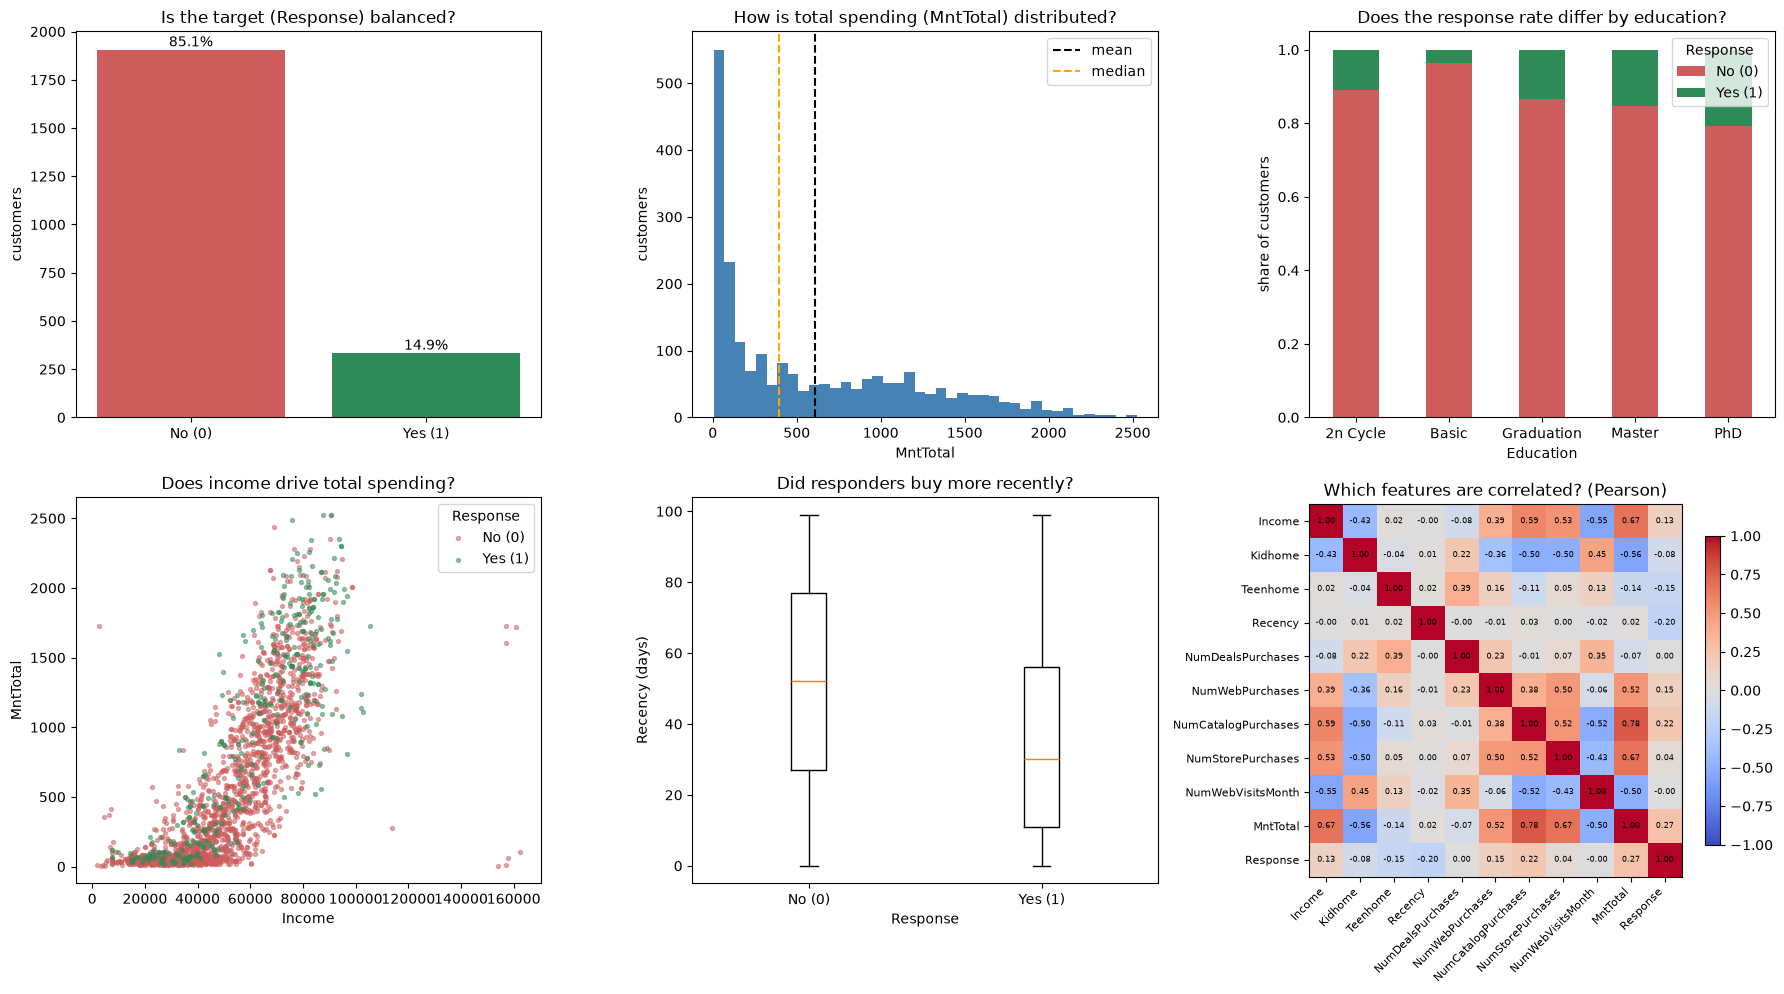

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
labels = ["No (0)", "Yes (1)"]
colors = ["indianred", "seagreen"]
no_outlier = df_stats[df_stats["Income"] < 200_000]

vc = df_stats[TARGET_CLF].value_counts().sort_index()
axes[0, 0].bar(labels, vc.values, color=colors)
for i, v in enumerate(vc.values):
    axes[0, 0].text(i, v, f"{100 * v / vc.sum():.1f}%", ha="center", va="bottom")
axes[0, 0].set(title=f"Is the target ({TARGET_CLF}) balanced?", ylabel="customers")

axes[0, 1].hist(df_stats[TARGET_REG], bins=40, color="steelblue")
axes[0, 1].axvline(df_stats[TARGET_REG].mean(), color="k", linestyle="--", label="mean")
axes[0, 1].axvline(df_stats[TARGET_REG].median(), color="orange", linestyle="--", label="median")
axes[0, 1].set(title=f"How is total spending ({TARGET_REG}) distributed?", xlabel=TARGET_REG, ylabel="customers")
axes[0, 1].legend()

pd.crosstab(df_stats["Education"], df_stats[TARGET_CLF], normalize="index").plot(
    kind="bar", stacked=True, ax=axes[0, 2], rot=0, color=colors)
axes[0, 2].set(title="Does the response rate differ by education?", ylabel="share of customers")
axes[0, 2].legend(labels, title=TARGET_CLF)

for k, color, label in zip([0, 1], colors, labels):
    part = no_outlier[no_outlier[TARGET_CLF] == k]
    axes[1, 0].scatter(part["Income"], part[TARGET_REG], s=8, alpha=0.5, color=color, label=label)
axes[1, 0].set(title="Does income drive total spending?", xlabel="Income", ylabel=TARGET_REG)
axes[1, 0].legend(title=TARGET_CLF)

axes[1, 1].boxplot([df_stats.loc[df_stats[TARGET_CLF] == k, "Recency"] for k in [0, 1]], tick_labels=labels)
axes[1, 1].set(title="Did responders buy more recently?", xlabel=TARGET_CLF, ylabel="Recency (days)")

heat_cols = ["Income", "Kidhome", "Teenhome", "Recency", "NumDealsPurchases", "NumWebPurchases",
             "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth", TARGET_REG, TARGET_CLF]
corr = df_stats[heat_cols].corr()
im = axes[1, 2].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[1, 2].set_xticks(range(len(heat_cols)), heat_cols, rotation=45, ha="right", fontsize=8)
axes[1, 2].set_yticks(range(len(heat_cols)), heat_cols, fontsize=8)
for i in range(len(heat_cols)):
    for j in range(len(heat_cols)):
        axes[1, 2].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
axes[1, 2].set_title("Which features are correlated? (Pearson)")
fig.colorbar(im, ax=axes[1, 2], shrink=0.8)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_01_explore.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Curățarea datelor

In [8]:
df = df_raw.copy()

df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])

df = df.drop_duplicates()

df.loc[df["Income"] == 666666, "Income"] = np.nan
df.loc[df["Year_Birth"] < 1920, "Year_Birth"] = np.nan

df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single", "Absurd": "Other", "YOLO": "Other"})
df["Education"] = df["Education"].replace({"2n Cycle": "Master"})

REFERENCE_DATE = pd.Timestamp("2014-12-31")
df["Customer_Days"] = (REFERENCE_DATE - pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")).dt.days
df = df.drop(columns=["Dt_Customer"])

df[TARGET_REG] = df[MNT_COLS].sum(axis=1)

df.to_csv(f"{DATA_DIR}/clean.csv", index=False)
print("before:", df_raw.shape, "-> after:", df.shape)
print("missing after cleaning (filled later, inside the pipeline):", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("Education:", df["Education"].value_counts().to_dict())
print("Marital_Status:", df["Marital_Status"].value_counts().to_dict())

before: (2240, 29) -> after: (2058, 27)
missing after cleaning (filled later, inside the pipeline): {'Year_Birth': 3, 'Income': 25}
Education: {'Graduation': 1030, 'Master': 529, 'PhD': 450, 'Basic': 49}
Marital_Status: {'Married': 795, 'Together': 521, 'Single': 451, 'Divorced': 216, 'Widow': 71, 'Other': 4}


## 4. Atributele, seturile de date și designul mulțimii de antrenament

In [9]:
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold

LEAKY_R = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumDealsPurchases"]

Xc = df.drop(columns=[TARGET_CLF, TARGET_REG])
yc = (df[TARGET_CLF] == POS_CLASS).astype(int)

Xr = df.drop(columns=[TARGET_REG, TARGET_CLF] + MNT_COLS + LEAKY_R)
yr = df[TARGET_REG]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=SEED)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=SEED)

num_cols_c = Xc_train.select_dtypes(include="number").columns.tolist()
num_cols_r = Xr_train.select_dtypes(include="number").columns.tolist()

cv_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_r = KFold(n_splits=5, shuffle=True, random_state=SEED)

print("classification: train", Xc_train.shape, "test", Xc_test.shape,
      f"| class 1: train {yc_train.mean():.3f}, test {yc_test.mean():.3f}")
print("regression:     train", Xr_train.shape, "test", Xr_test.shape)
print("regression features:", Xr_train.columns.tolist())

classification: train (1646, 25) test (412, 25) | class 1: train 0.152, test 0.153
regression:     train (1646, 15) test (412, 15)
regression features: ['Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Customer_Days']


## 5. Preprocesarea în pipeline
### 5.1 Valorile lipsă: merită un indicator de lipsă?

In [10]:
no_income = Xc_train["Income"].isna()
print(f"rows without Income in train: {no_income.sum()} | response rate without Income: "
      f"{yc_train[no_income].mean():.3f} vs with Income: {yc_train[~no_income].mean():.3f}")
print("-> difference, but very few rows: add_indicator is tested in the grid search (8.1)")

rows without Income in train: 22 | response rate without Income: 0.045 vs with Income: 0.153
-> difference, but very few rows: add_indicator is tested in the grid search (8.1)


### 5.2 Scalarea: SVM pe atribute nescalate și SVR pe ținta nescalată

In [11]:
from sklearn.svm import SVC, SVR
from sklearn.linear_model import LogisticRegression, LinearRegression

variants_c = {
    "SVC rbf, no scaling": make_pipe(SVC(class_weight="balanced"), num_cols_c, scaler="passthrough"),
    "SVC rbf + StandardScaler": make_pipe(SVC(class_weight="balanced"), num_cols_c),
    "SVC rbf + RobustScaler": make_pipe(SVC(class_weight="balanced"), num_cols_c, scaler=RobustScaler()),
}
table_scale_c, _ = compare(variants_c, Xc_train, yc_train, "classification", cv_c)
display(table_scale_c[["PR_AUC", "PR_AUC_std", "recall", "bal_acc"]].round(3))

variants_r = {
    "SVR rbf, no scaling": make_pipe(SVR(), num_cols_r, scaler="passthrough"),
    "SVR rbf + scaling X": make_pipe(SVR(), num_cols_r),
    "SVR rbf + scaling X and y": TransformedTargetRegressor(make_pipe(SVR(), num_cols_r), transformer=StandardScaler()),
}
table_scale_r, _ = compare(variants_r, Xr_train, yr_train, "regression", cv_r)
display(table_scale_r[["MAE", "MAE_std", "R2"]].round(3))

,PR_AUC,PR_AUC_std,recall,bal_acc
model,,,,
SVC rbf + RobustScaler,0.560,0.098,0.756,0.790
SVC rbf + StandardScaler,0.540,0.081,0.752,0.789
"SVC rbf, no scaling",0.307,0.045,0.376,0.603


,MAE,MAE_std,R2
model,,,
SVR rbf + scaling X and y,193.823,10.668,0.786
"SVR rbf, no scaling",386.154,11.594,0.237
SVR rbf + scaling X,456.010,11.878,0.010


### 5.3 Tratarea data leakage

In [12]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score

rng = np.random.default_rng(SEED)
X_noise = rng.normal(size=(200, 5000))
y_noise = rng.integers(0, 2, size=200)
cv_noise = StratifiedKFold(5, shuffle=True, random_state=SEED)

X_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
wrong = cross_val_score(LogisticRegression(max_iter=1000), X_selected, y_noise, cv=cv_noise)
right = cross_val_score(Pipeline([("select", SelectKBest(f_classif, k=20)), ("model", LogisticRegression(max_iter=1000))]),
                        X_noise, y_noise, cv=cv_noise)
print(f"selection BEFORE CV: accuracy {wrong.mean():.3f} (optimistic) | selection INSIDE the pipeline: {right.mean():.3f}")

selection BEFORE CV: accuracy 0.825 (optimistic) | selection INSIDE the pipeline: 0.595


In [13]:
from sklearn.ensemble import HistGradientBoostingRegressor

Xr_leaky = df.drop(columns=[TARGET_REG, TARGET_CLF] + MNT_COLS).loc[Xr_train.index]
leak_models = {
    "linear, WITH Num*Purchases": (make_pipe(LinearRegression(), Xr_leaky.select_dtypes("number").columns.tolist()), Xr_leaky),
    "linear, without (honest)": (make_pipe(LinearRegression(), num_cols_r), Xr_train),
    "HistGB, WITH Num*Purchases": (make_pipe(HistGradientBoostingRegressor(random_state=SEED),
                                              Xr_leaky.select_dtypes("number").columns.tolist(), scaler="passthrough"), Xr_leaky),
    "HistGB, without (honest)": (make_pipe(HistGradientBoostingRegressor(random_state=SEED), num_cols_r,
                                            scaler="passthrough"), Xr_train),
}
rows = []
for name, (model, X) in leak_models.items():
    row, _ = evaluate(model, X, yr_train, "regression", cv_r)
    rows.append({"model": name, **row})
display(pd.DataFrame(rows).set_index("model")[["MAE", "R2"]].round(3))

,MAE,R2
model,,
"linear, WITH Num*Purchases",180.063,0.805
"linear, without (honest)",233.208,0.715
"HistGB, WITH Num*Purchases",129.255,0.856
"HistGB, without (honest)",191.668,0.786


## 6. Dezechilibrul claselor

In [14]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

print(f"class 1 in train: {yc_train.mean():.3f} | imbalance ratio: {(1 - yc_train.mean()) / yc_train.mean():.2f}")


def resampled(sampler):
    return ImbPipeline([("prep", make_prep(num_cols_c)), ("sampler", sampler),
                        ("model", LogisticRegression(max_iter=1000))])


strategies = {
    "none": make_pipe(LogisticRegression(max_iter=1000), num_cols_c),
    "class_weight=balanced": make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced"), num_cols_c),
    "random oversampling": resampled(RandomOverSampler(random_state=SEED)),
    "SMOTE": resampled(SMOTE(random_state=SEED)),
    "random undersampling": resampled(RandomUnderSampler(random_state=SEED)),
}
table_imb, _ = compare(strategies, Xc_train, yc_train, "classification", cv_c)
display(table_imb[["recall", "precision", "F1", "bal_acc", "PR_AUC", "PR_AUC_std"]].round(3))

class 1 in train: 0.152 | imbalance ratio: 5.58


,recall,precision,F1,bal_acc,PR_AUC,PR_AUC_std
model,,,,,,
none,0.428,0.650,0.509,0.693,0.604,0.064
class_weight=balanced,0.788,0.439,0.562,0.802,0.601,0.065
random oversampling,0.772,0.432,0.552,0.794,0.596,0.068
SMOTE,0.760,0.441,0.556,0.793,0.590,0.065
random undersampling,0.772,0.413,0.537,0.787,0.572,0.053


## 7. Alegerea modelelor, antrenarea și evaluarea inițială (validare încrucișată)

In [15]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)

N_TREES = 300
models_c = {
    "baseline": make_pipe(DummyClassifier(strategy="prior"), num_cols_c),
    "logistic regression": make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced"), num_cols_c),
    "kNN (k=15)": make_pipe(KNeighborsClassifier(n_neighbors=15), num_cols_c),
    "decision tree (depth 5)": make_pipe(DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEED),
                                         num_cols_c, scaler="passthrough"),
    "SVM (rbf)": make_pipe(SVC(class_weight="balanced"), num_cols_c),
    "random forest": make_pipe(RandomForestClassifier(N_TREES, min_samples_leaf=5, class_weight="balanced",
                                                      random_state=SEED, n_jobs=-1), num_cols_c, scaler="passthrough"),
    "HistGB": make_pipe(HistGradientBoostingClassifier(learning_rate=0.05, max_iter=1000, early_stopping=True,
                                                       class_weight="balanced", random_state=SEED),
                        num_cols_c, scaler="passthrough"),
}
models_r = {
    "baseline (mean)": make_pipe(DummyRegressor(), num_cols_r),
    "linear regression": make_pipe(LinearRegression(), num_cols_r),
    "kNN (k=15)": make_pipe(KNeighborsRegressor(n_neighbors=15), num_cols_r),
    "decision tree (depth 5)": make_pipe(DecisionTreeRegressor(max_depth=5, random_state=SEED), num_cols_r,
                                         scaler="passthrough"),
    "SVR (rbf)": TransformedTargetRegressor(make_pipe(SVR(), num_cols_r), transformer=StandardScaler()),
    "random forest": make_pipe(RandomForestRegressor(N_TREES, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
                               num_cols_r, scaler="passthrough"),
    "HistGB": make_pipe(HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_iter=1000,
                                                      early_stopping=True, random_state=SEED),
                        num_cols_r, scaler="passthrough"),
}
table_init_c, folds_init_c = compare(models_c, Xc_train, yc_train, "classification", cv_c)
table_init_r, folds_init_r = compare(models_r, Xr_train, yr_train, "regression", cv_r)
display(table_init_c.round(3))
display(table_init_r.round(3))

,PR_AUC,PR_AUC_std,PR_AUC_train,ROC_AUC,F1,recall,precision,bal_acc,fit_time_s
model,,,,,,,,,
logistic regression,0.601,0.065,0.639,0.884,0.562,0.788,0.439,0.802,0.046
random forest,0.566,0.040,0.988,0.873,0.523,0.636,0.447,0.747,0.835
HistGB,0.553,0.038,0.950,0.859,0.509,0.588,0.459,0.730,0.534
SVM (rbf),0.540,0.081,0.839,0.872,0.552,0.752,0.437,0.789,0.086
kNN (k=15),0.462,0.078,0.581,0.814,0.296,0.192,0.674,0.587,0.030
decision tree (depth 5),0.322,0.043,0.582,0.678,0.404,0.600,0.305,0.677,0.032
baseline,0.152,0.000,0.152,0.500,0.000,0.000,0.000,0.500,0.028


,MAE,MAE_std,MAE_train,RMSE,R2,fit_time_s
model,,,,,,
HistGB,185.509,11.981,134.578,277.071,0.795,0.353
random forest,192.161,11.598,129.481,285.585,0.783,0.741
SVR (rbf),193.823,10.668,146.609,283.670,0.786,0.119
decision tree (depth 5),216.836,11.356,177.224,323.663,0.720,0.026
linear regression,233.208,12.099,230.482,326.450,0.715,0.027
kNN (k=15),233.679,10.417,218.172,332.069,0.706,0.032
baseline (mean),527.012,10.058,526.645,614.621,-0.003,0.025


### 7.1 Curbele ROC și precizie–recall (predicții out-of-fold pe train)

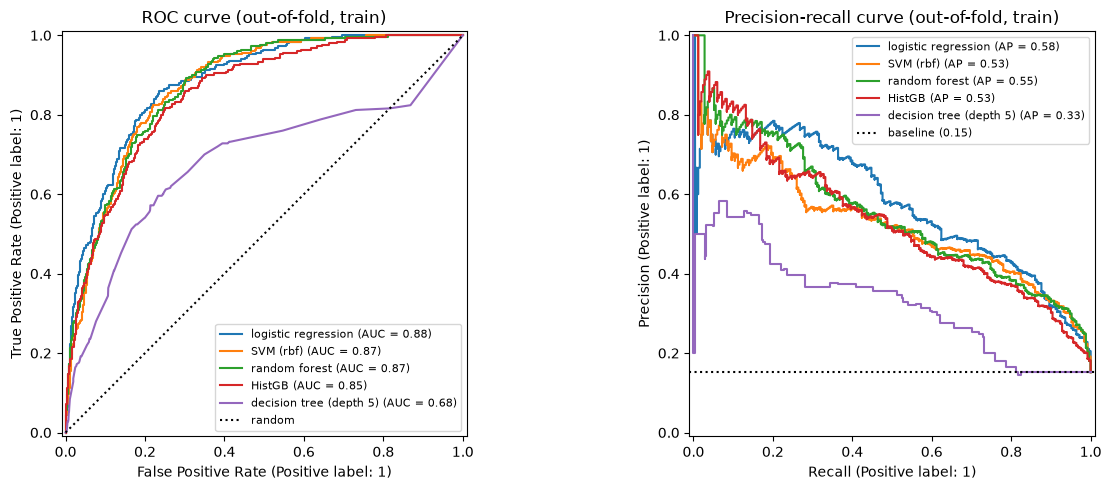

In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay


def oof_scores(model, X, y, cv):
    method = "decision_function" if not hasattr(model, "predict_proba") else "predict_proba"
    s = cross_val_predict(model, X, y, cv=cv, method=method)
    return s[:, 1] if s.ndim == 2 else s


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in ["logistic regression", "SVM (rbf)", "random forest", "HistGB", "decision tree (depth 5)"]:
    s = oof_scores(models_c[name], Xc_train, yc_train, cv_c)
    RocCurveDisplay.from_predictions(yc_train, s, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(yc_train, s, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k:", label="random")
axes[1].axhline(yc_train.mean(), color="k", linestyle=":", label=f"baseline ({yc_train.mean():.2f})")
axes[0].set_title("ROC curve (out-of-fold, train)")
axes[1].set_title("Precision-recall curve (out-of-fold, train)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_02_roc_pr_cv.png", dpi=150, bbox_inches="tight")
plt.show()

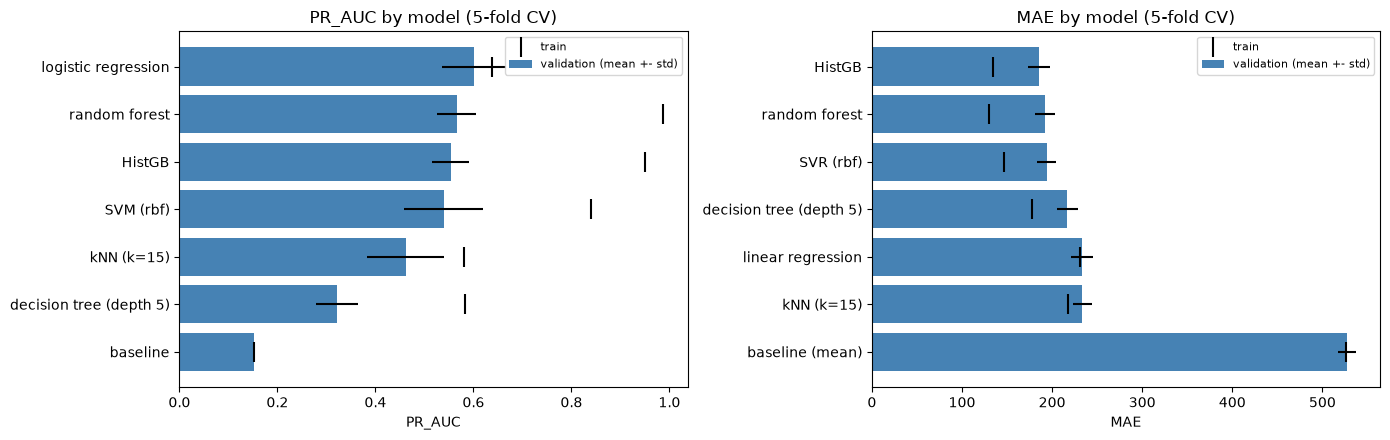

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, table, main in [(axes[0], table_init_c, "PR_AUC"), (axes[1], table_init_r, "MAE")]:
    t = table.iloc[::-1]
    ax.barh(t.index, t[main], xerr=t[f"{main}_std"], color="steelblue", label="validation (mean +- std)")
    ax.scatter(t[f"{main}_train"], t.index, color="k", marker="|", s=200, label="train")
    ax.set(title=f"{main} by model (5-fold CV)", xlabel=main)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_03_cv_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Selecția modelelor: grid search și analiza de senzitivitate
### 8.1 Regresia logistică: GridSearchCV + curba de validare pentru C

best: {'model__C': np.float64(100.0), 'prep__num__impute__add_indicator': True, 'prep__num__scale': StandardScaler()} | CV PR-AUC = 0.605


,param_model__C,param_prep__num__scale,param_prep__num__impute__add_indicator,mean_test_score,std_test_score,mean_train_score
22,100.0,StandardScaler(),True,0.605,0.067,0.645
18,10.0,StandardScaler(),True,0.605,0.067,0.645
14,1.0,StandardScaler(),True,0.605,0.068,0.645
10,0.1,StandardScaler(),True,0.605,0.071,0.646
23,100.0,RobustScaler(),True,0.605,0.064,0.645


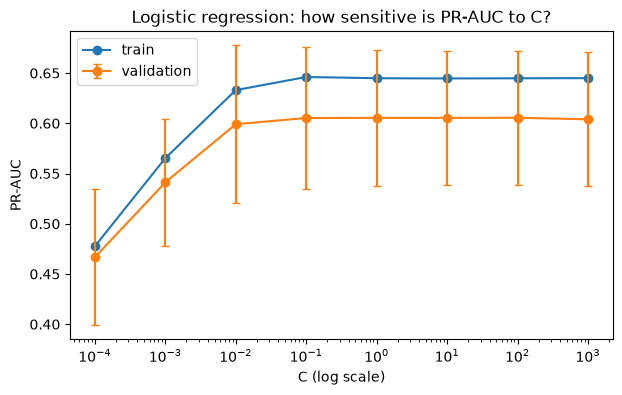

validation PR-AUC by C: {np.float64(0.0001): np.float64(0.467), np.float64(0.001): np.float64(0.541), np.float64(0.01): np.float64(0.599), np.float64(0.1): np.float64(0.605), np.float64(1.0): np.float64(0.605), np.float64(10.0): np.float64(0.605), np.float64(100.0): np.float64(0.605), np.float64(1000.0): np.float64(0.604)}


In [18]:
from sklearn.model_selection import GridSearchCV, validation_curve

grid_lr = GridSearchCV(
    make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced"), num_cols_c),
    {"model__C": np.logspace(-3, 2, 6),
     "prep__num__scale": [StandardScaler(), RobustScaler()],
     "prep__num__impute__add_indicator": [False, True]},
    cv=cv_c, scoring="average_precision", n_jobs=-1, return_train_score=True)
grid_lr.fit(Xc_train, yc_train)
print("best:", grid_lr.best_params_, f"| CV PR-AUC = {grid_lr.best_score_:.3f}")
cols = ["param_model__C", "param_prep__num__scale",
        "param_prep__num__impute__add_indicator", "mean_test_score", "std_test_score", "mean_train_score"]
display(pd.DataFrame(grid_lr.cv_results_).sort_values("rank_test_score")[cols].head(5).round(3))

C_range = np.logspace(-4, 3, 8)
train_s, val_s = validation_curve(grid_lr.best_estimator_, Xc_train, yc_train, param_name="model__C",
                                  param_range=C_range, cv=cv_c, scoring="average_precision", n_jobs=-1)
plt.figure(figsize=(7, 4))
plt.plot(C_range, train_s.mean(axis=1), "o-", label="train")
plt.errorbar(C_range, val_s.mean(axis=1), yerr=val_s.std(axis=1), fmt="o-", capsize=3, label="validation")
plt.xscale("log")
plt.gca().set(xlabel="C (log scale)", ylabel="PR-AUC", title="Logistic regression: how sensitive is PR-AUC to C?")
plt.legend()
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_04_lr_C_curve.png", dpi=150, bbox_inches="tight")
plt.show()
print("validation PR-AUC by C:", dict(zip(C_range.round(4), val_s.mean(axis=1).round(3))))

### 8.2 SVM (clasificare): grid pe kernel, C, γ + harta C × γ

SVC search: 7 s | best: {'model__C': np.float64(100.0), 'model__gamma': np.float64(0.001), 'model__kernel': 'rbf'} | CV PR-AUC = 0.606


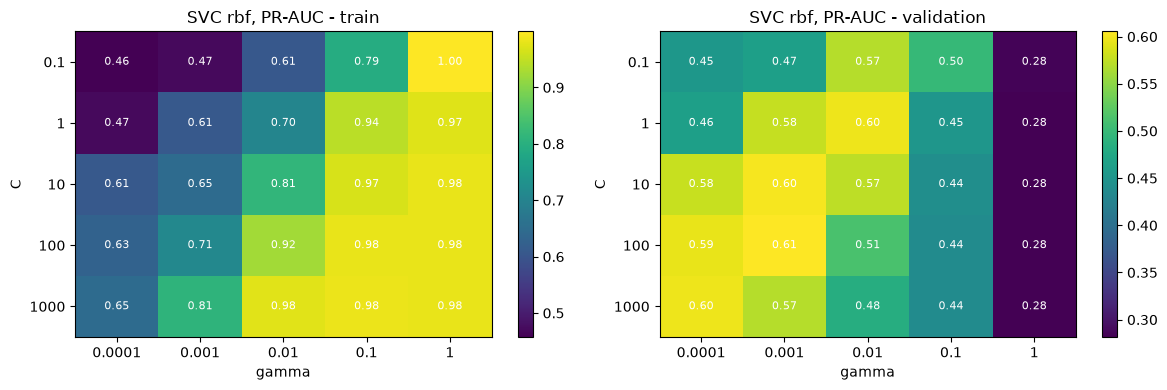

In [19]:
param_grid_svc = [
    {"model__kernel": ["linear"], "model__C": np.logspace(-2, 1, 4)},
    {"model__kernel": ["rbf"], "model__C": np.logspace(-1, 3, 5), "model__gamma": np.logspace(-4, 0, 5)},
]
grid_svc = GridSearchCV(make_pipe(SVC(class_weight="balanced"), num_cols_c), param_grid_svc, cv=cv_c,
                        scoring="average_precision", n_jobs=-1, return_train_score=True)
t0 = time.time()
grid_svc.fit(Xc_train, yc_train)
print(f"SVC search: {time.time() - t0:.0f} s | best: {grid_svc.best_params_} | CV PR-AUC = {grid_svc.best_score_:.3f}")


def heatmaps_C_gamma(grid, prefix="model__", fixed=None, title="", error=False):
    res = pd.DataFrame(grid.cv_results_)
    res = res[res[f"param_{prefix}kernel"] == "rbf"]
    for key, value in (fixed or {}).items():
        res = res[res[f"param_{key}"] == value]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, split in zip(axes, ["train", "test"]):
        table = res.pivot_table(index=f"param_{prefix}C", columns=f"param_{prefix}gamma", values=f"mean_{split}_score")
        if error:
            table = -table
        im = ax.imshow(table.values, cmap="viridis_r" if error else "viridis", aspect="auto")
        ax.set_xticks(range(table.shape[1]), [f"{g:g}" for g in table.columns])
        ax.set_yticks(range(table.shape[0]), [f"{c:g}" for c in table.index])
        for i in range(table.shape[0]):
            for j in range(table.shape[1]):
                ax.text(j, i, f"{table.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
        ax.set(xlabel="gamma", ylabel="C", title=f"{title} - {'validation' if split == 'test' else 'train'}")
        fig.colorbar(im, ax=ax)
    plt.tight_layout()
    return fig


heatmaps_C_gamma(grid_svc, title="SVC rbf, PR-AUC")
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_05_svc_C_gamma.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.3 SVR (regresie): grid pe kernel, C, γ, ε

SVR search: 21 s | best: {'regressor__model__C': np.float64(100.0), 'regressor__model__epsilon': 0.05, 'regressor__model__gamma': np.float64(0.01), 'regressor__model__kernel': 'rbf'} | CV MAE = 199.1


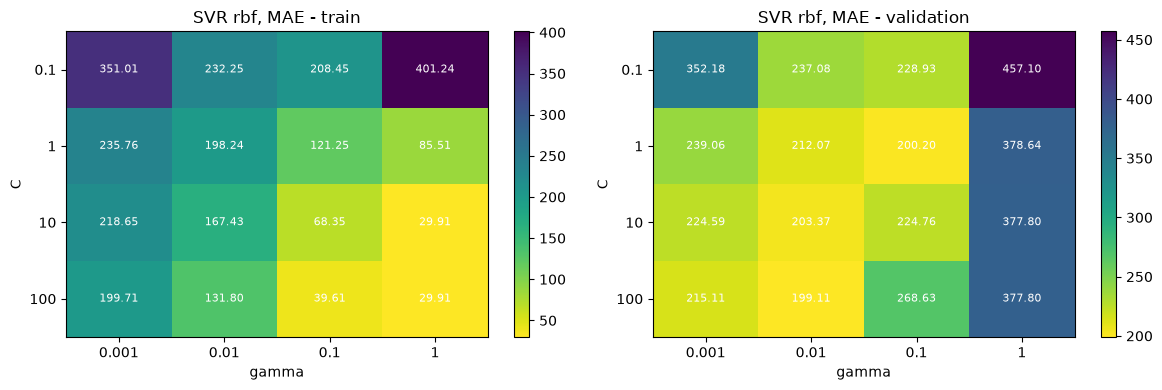

CV MAE by epsilon: {0.05: 199.1, 0.1: 201.2, 0.3: 210.5}


In [20]:
prefix = "regressor__model__"
param_grid_svr = [
    {f"{prefix}kernel": ["linear"], f"{prefix}C": np.logspace(-2, 1, 4), f"{prefix}epsilon": [0.05, 0.1, 0.3]},
    {f"{prefix}kernel": ["rbf"], f"{prefix}C": np.logspace(-1, 2, 4), f"{prefix}gamma": np.logspace(-3, 0, 4),
     f"{prefix}epsilon": [0.05, 0.1, 0.3]},
]
grid_svr = GridSearchCV(TransformedTargetRegressor(make_pipe(SVR(), num_cols_r), transformer=StandardScaler()),
                        param_grid_svr, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=-1, return_train_score=True)
t0 = time.time()
grid_svr.fit(Xr_train, yr_train)
print(f"SVR search: {time.time() - t0:.0f} s | best: {grid_svr.best_params_} | CV MAE = {-grid_svr.best_score_:.1f}")

heatmaps_C_gamma(grid_svr, prefix=prefix, error=True, title="SVR rbf, MAE",
                 fixed={f"{prefix}epsilon": grid_svr.best_params_.get(f"{prefix}epsilon")})
plt.show()

res = pd.DataFrame(grid_svr.cv_results_)
best = grid_svr.best_params_
mask = (res[f"param_{prefix}kernel"] == best[f"{prefix}kernel"]) & (res[f"param_{prefix}C"] == best[f"{prefix}C"])
if best[f"{prefix}kernel"] == "rbf":
    mask &= res[f"param_{prefix}gamma"] == best[f"{prefix}gamma"]
print("CV MAE by epsilon:", dict(zip(res.loc[mask, f"param_{prefix}epsilon"], (-res.loc[mask, "mean_test_score"]).round(1))))

### 8.4 HistGradientBoosting: RandomizedSearchCV + senzitivitatea la rata de învățare

In [21]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

space = {
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__max_leaf_nodes": randint(8, 65),
    "model__min_samples_leaf": randint(10, 81),
    "model__l2_regularization": loguniform(1e-3, 10),
}
searches = {}
for task, base, X, y, cv, scoring in [
        ("classification", models_c["HistGB"], Xc_train, yc_train, cv_c, "average_precision"),
        ("regression", models_r["HistGB"], Xr_train, yr_train, cv_r, "neg_mean_absolute_error")]:
    search = RandomizedSearchCV(base, space, n_iter=30, cv=cv, scoring=scoring, random_state=SEED, n_jobs=-1,
                                return_train_score=True).fit(X, y)
    searches[task] = search
    sign = -1 if scoring.startswith("neg_") else 1
    table = table_init_c if task == "classification" else table_init_r
    default = table.loc["HistGB"].iloc[0]
    best_std = search.cv_results_["std_test_score"][search.best_index_]
    print(f"{task}: default {default:.3f} -> tuned {sign * search.best_score_:.3f} (std {best_std:.3f})")
    print("   best:", {k.replace("model__", ""): round(v, 4) for k, v in search.best_params_.items()})

classification: default 0.553 -> tuned 0.603 (std 0.032)
   best: {'l2_regularization': np.float64(0.0292), 'learning_rate': np.float64(0.0472), 'max_leaf_nodes': 54, 'min_samples_leaf': 71}


regression: default 185.509 -> tuned 182.502 (std 11.266)
   best: {'l2_regularization': np.float64(2.7527), 'learning_rate': np.float64(0.1011), 'max_leaf_nodes': 16, 'min_samples_leaf': 48}


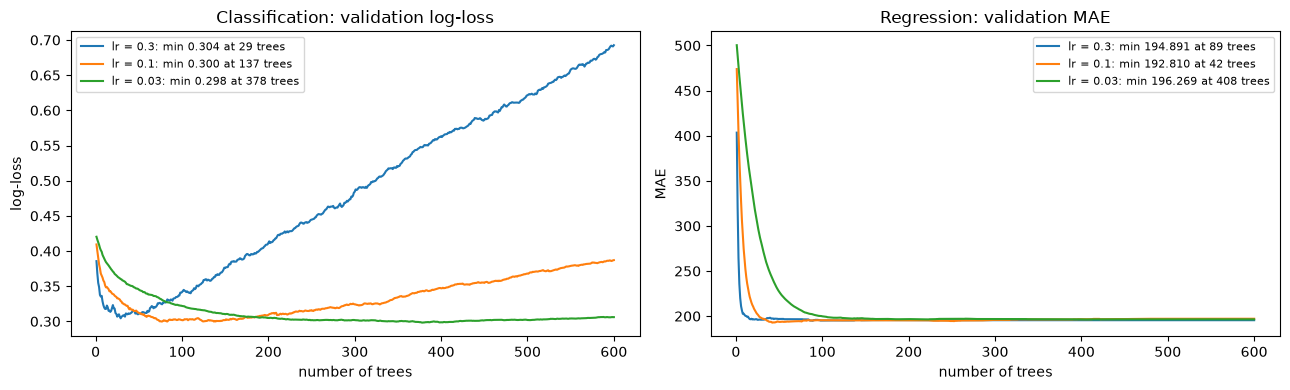

In [22]:
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.metrics import log_loss, mean_absolute_error

Xc_f, Xc_v, yc_f, yc_v = train_test_split(Xc_train, yc_train, test_size=0.2, stratify=yc_train, random_state=SEED)
Xr_f, Xr_v, yr_f, yr_v = train_test_split(Xr_train, yr_train, test_size=0.2, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lr in [0.3, 0.1, 0.03]:
    gb_c = make_pipe(GradientBoostingClassifier(learning_rate=lr, n_estimators=600, max_depth=3, random_state=SEED),
                     num_cols_c, scaler="passthrough").fit(Xc_f, yc_f)
    loss_c = [log_loss(yc_v, p[:, 1]) for p in gb_c["model"].staged_predict_proba(gb_c["prep"].transform(Xc_v))]
    gb_r = make_pipe(GradientBoostingRegressor(loss="absolute_error", learning_rate=lr, n_estimators=600, max_depth=3,
                                               random_state=SEED), num_cols_r, scaler="passthrough").fit(Xr_f, yr_f)
    loss_r = [mean_absolute_error(yr_v, p) for p in gb_r["model"].staged_predict(gb_r["prep"].transform(Xr_v))]
    for ax, loss in [(axes[0], loss_c), (axes[1], loss_r)]:
        best = int(np.argmin(loss))
        ax.plot(range(1, len(loss) + 1), loss, label=f"lr = {lr}: min {loss[best]:.3f} at {best + 1} trees")
axes[0].set(title="Classification: validation log-loss", xlabel="number of trees", ylabel="log-loss")
axes[1].set(title="Regression: validation MAE", xlabel="number of trees", ylabel="MAE")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_06_boosting_lr.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.5 Cât de optimist e scorul celei mai bune combinații? (nested CV)

In [23]:
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
inner_grid = GridSearchCV(make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced"), num_cols_c),
                          {"model__C": np.logspace(-3, 2, 6), "prep__num__impute__add_indicator": [False, True]},
                          cv=inner, scoring="average_precision", n_jobs=-1)
nested = cross_val_score(inner_grid, Xc_train, yc_train, cv=cv_c, scoring="average_precision")
print(f"logistic regression: grid best_score_ {grid_lr.best_score_:.3f} | nested CV {nested.mean():.3f} +- {nested.std():.3f}")

logistic regression: grid best_score_ 0.605 | nested CV 0.601 +- 0.066


## 9. Ansambluri din modele diferite și comparația finală

In [24]:
from sklearn.ensemble import VotingClassifier, StackingClassifier, VotingRegressor, StackingRegressor
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import RidgeCV

best_lr = grid_lr.best_estimator_
best_svc = grid_svc.best_estimator_
best_svr = grid_svr.best_estimator_
hgb_c = searches["classification"].best_estimator_
hgb_r_default = models_r["HistGB"]

members_c = [("logistic", best_lr),
             ("svm", CalibratedClassifierCV(best_svc, method="sigmoid", cv=3)),
             ("histgb", hgb_c)]
members_r = [("linear", models_r["linear regression"]), ("svr", best_svr), ("rf", models_r["random forest"])]

final_models_c = {
    "baseline": models_c["baseline"],
    "logistic regression (tuned)": best_lr,
    "SVM (tuned)": best_svc,
    "random forest": models_c["random forest"],
    "HistGB (tuned)": hgb_c,
    "voting (soft)": VotingClassifier(members_c, voting="soft", n_jobs=-1),
    "stacking": StackingClassifier(members_c, final_estimator=LogisticRegression(class_weight="balanced"), cv=5, n_jobs=-1),
}
final_models_r = {
    "baseline (mean)": models_r["baseline (mean)"],
    "linear regression": models_r["linear regression"],
    "SVR (tuned)": best_svr,
    "random forest": models_r["random forest"],
    "HistGB (default)": hgb_r_default,
    "HistGB (tuned)": searches["regression"].best_estimator_,
    "voting": VotingRegressor(members_r, n_jobs=-1),
    "stacking": StackingRegressor(members_r, final_estimator=RidgeCV(), cv=5, n_jobs=-1),
}
table_c, folds_c = compare(final_models_c, Xc_train, yc_train, "classification", cv_c)
table_r, folds_r = compare(final_models_r, Xr_train, yr_train, "regression", cv_r)
display(table_c.round(3))
display(table_r.round(3))
pd.concat([table_c.assign(task="classification"), table_r.assign(task="regression")]).to_csv(
    f"{RESULTS_DIR}/{MY_NAME}_cv_results.csv")

,PR_AUC,PR_AUC_std,PR_AUC_train,ROC_AUC,F1,recall,precision,bal_acc,fit_time_s
model,,,,,,,,,
voting (soft),0.645,0.054,0.783,0.897,0.565,0.608,0.537,0.755,0.757
stacking,0.642,0.052,0.803,0.895,0.562,0.800,0.437,0.805,5.399
SVM (tuned),0.606,0.063,0.711,0.882,0.551,0.776,0.430,0.795,0.078
logistic regression (tuned),0.605,0.067,0.645,0.882,0.562,0.800,0.436,0.806,0.053
HistGB (tuned),0.603,0.032,0.892,0.882,0.545,0.688,0.459,0.768,0.521
random forest,0.566,0.040,0.988,0.873,0.523,0.636,0.447,0.747,0.847
baseline,0.152,0.000,0.152,0.500,0.000,0.000,0.000,0.500,0.029


,MAE,MAE_std,MAE_train,RMSE,R2,fit_time_s
model,,,,,,
HistGB (tuned),182.502,11.266,151.237,276.404,0.796,0.211
HistGB (default),185.509,11.981,134.578,277.071,0.795,0.566
stacking,186.147,10.092,127.027,277.591,0.795,10.868
random forest,192.161,11.598,129.481,285.585,0.783,0.997
voting,193.030,11.064,153.374,281.489,0.788,2.297
SVR (tuned),199.112,10.905,131.799,302.046,0.757,0.642
linear regression,233.208,12.099,230.482,326.450,0.715,0.029
baseline (mean),527.012,10.058,526.645,614.621,-0.003,0.028


In [25]:
ttest_pair(folds_c, table_c.index[0], table_c.index[1], len(Xc_train))
ttest_pair(folds_c, table_c.index[0], "logistic regression (tuned)", len(Xc_train))
ttest_pair(folds_c, "SVM (tuned)", "logistic regression (tuned)", len(Xc_train))
print()
ttest_pair(folds_r, table_r.index[0], table_r.index[1], len(Xr_train))
ttest_pair(folds_r, "HistGB (default)", "random forest", len(Xr_train))
_ = ttest_pair(folds_r, "SVR (tuned)", "linear regression", len(Xr_train))

voting (soft) vs stacking: diff = +0.002, t = 0.44, p = 0.685 -> NOT significant
voting (soft) vs logistic regression (tuned): diff = +0.039, t = 1.84, p = 0.140 -> NOT significant
SVM (tuned) vs logistic regression (tuned): diff = +0.000, t = 0.01, p = 0.995 -> NOT significant

HistGB (tuned) vs HistGB (default): diff = -3.006, t = -2.05, p = 0.109 -> NOT significant
HistGB (default) vs random forest: diff = -6.653, t = -2.32, p = 0.081 -> NOT significant
SVR (tuned) vs linear regression: diff = -34.096, t = -5.91, p = 0.004 -> significant


### 9.1 Contribuție: atribute agregate pentru SVM-ul RBF

In [26]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import clone

ACC_COLS = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
PURCHASE_COLS = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]


def add_features(X):
    X = X.copy()
    X["AcceptedTotal"] = X[ACC_COLS].sum(axis=1)
    X["Children"] = X["Kidhome"] + X["Teenhome"]
    X["Age"] = 2014 - X["Year_Birth"]
    X["SpendPerPurchase"] = X[MNT_COLS].sum(axis=1) / X[PURCHASE_COLS].sum(axis=1).clip(lower=1)
    return X.drop(columns=ACC_COLS + ["Kidhome", "Teenhome", "Year_Birth"])


new_num = add_features(Xc_train.head()).select_dtypes("number").columns.tolist()
svc_new = Pipeline([("features", FunctionTransformer(add_features)),
                    ("svm", make_pipe(clone(best_svc["model"]), new_num))])

row_old, f_old = evaluate(best_svc, Xc_train, yc_train, "classification", cv_c)
row_new, f_new = evaluate(svc_new, Xc_train, yc_train, "classification", cv_c)
display(pd.DataFrame([row_old, row_new], index=["SVM, original features", "SVM, + aggregated features"])
        [["PR_AUC", "PR_AUC_std", "ROC_AUC", "F1", "recall"]].round(3))
t, p = corrected_ttest(f_new, f_old, len(Xc_train) * 4 / 5, len(Xc_train) / 5)
print(f"diff = {f_new.mean() - f_old.mean():+.3f}, t = {t:.2f}, p = {p:.3f}")

,PR_AUC,PR_AUC_std,ROC_AUC,F1,recall
"SVM, original features",0.606,0.063,0.882,0.551,0.776
"SVM, + aggregated features",0.625,0.072,0.882,0.540,0.756


diff = +0.020, t = 2.22, p = 0.090


## 10. Rețele neuronale (Keras)
### 10.1 Datele pentru Keras și prima comparație (overfitting vs. regularizare)

epochs run  params  \
task           variant                                             
classification big, no regularization                200  106753   
               big + EarlyStopping                    22  106753   
               big + Dropout 0.3 + ES                 32  106753   
               small (32, 16) + Dropout + ES          67    1537   
regression     big, no regularization                200  104193   
               big + EarlyStopping                    37  104193   
               big + Dropout 0.3 + ES                 49  104193   
               small (32, 16) + Dropout + ES         107    1217   

                                              validation PR-AUC / MAE  
task           variant                                                 
classification big, no regularization                           0.479  
               big + EarlyStopping                              0.522  
               big + Dropout 0.3 + ES                           0.597  
               small (32, 16) + Dropout + ES                    0.560  
regression     big, no regularization                         229.379  
               big + EarlyStopping                            196.586  
               big + Dropout 0.3 + ES                         186.739  
               small (32, 16) + Dropout + ES                  187.121

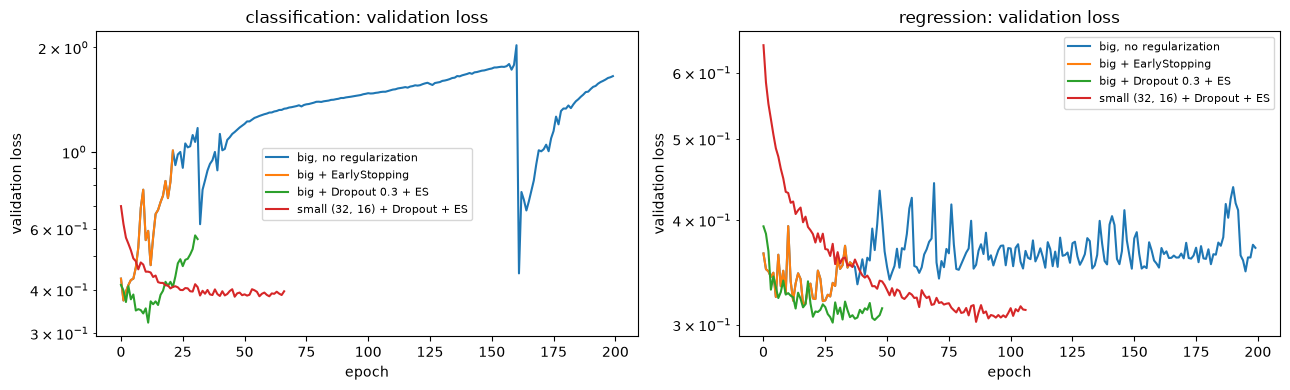

In [27]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import keras
from keras import layers, regularizers, callbacks
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import average_precision_score

prep_net_c = make_prep(num_cols_c).fit(Xc_f)
Ac_f, Ac_v = (prep_net_c.transform(d).astype("float32") for d in (Xc_f, Xc_v))
tc_f, tc_v = yc_f.to_numpy().astype("float32"), yc_v.to_numpy().astype("float32")

prep_net_r = make_prep(num_cols_r).fit(Xr_f)
Ar_f, Ar_v = (prep_net_r.transform(d).astype("float32") for d in (Xr_f, Xr_v))
y_scaler = StandardScaler().fit(yr_f.to_numpy().reshape(-1, 1))
tr_f, tr_v = (y_scaler.transform(d.to_numpy().reshape(-1, 1)).ravel().astype("float32") for d in (yr_f, yr_v))


def to_money(t_scaled):
    return y_scaler.inverse_transform(np.asarray(t_scaled).reshape(-1, 1)).ravel()


def balanced_weights(y):
    w = compute_class_weight("balanced", classes=np.array([0, 1]), y=np.asarray(y).astype(int))
    return {0: w[0], 1: w[1]}


def make_net(n_inputs, task, units=(32, 16), dropout=0.0, l2=0.0, lr=1e-3, loss=None):
    reg = regularizers.l2(l2) if l2 > 0 else None
    net = keras.Sequential([keras.Input(shape=(n_inputs,))])
    for u in units:
        net.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            net.add(layers.Dropout(dropout))
    if task == "classification":
        net.add(layers.Dense(1, activation="sigmoid"))
        net.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss=loss or "binary_crossentropy")
    else:
        net.add(layers.Dense(1))
        net.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss=loss or "mse")
    return net


def early_stop():
    return callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)


data_net = {"classification": (Ac_f, tc_f, Ac_v, tc_v), "regression": (Ar_f, tr_f, Ar_v, tr_v)}


def val_score(task, p, t_v):
    return average_precision_score(t_v, p) if task == "classification" else mean_absolute_error(yr_v, to_money(p))


BIG = (256, 256, 128)
variants = {"big, no regularization": dict(units=BIG, stop=False),
            "big + EarlyStopping": dict(units=BIG, stop=True),
            "big + Dropout 0.3 + ES": dict(units=BIG, dropout=0.3, stop=True),
            "small (32, 16) + Dropout + ES": dict(units=(32, 16), dropout=0.3, stop=True)}
rows, histories = [], {}
for task, (A_f, t_f, A_v, t_v) in data_net.items():
    for name, cfg in variants.items():
        cfg = dict(cfg)
        stop = cfg.pop("stop")
        keras.utils.set_random_seed(SEED)
        net = make_net(A_f.shape[1], task, loss="mae" if task == "regression" else None, **cfg)
        h = net.fit(A_f, t_f, validation_data=(A_v, t_v), epochs=200, batch_size=32, verbose=0,
                    callbacks=[early_stop()] if stop else [],
                    class_weight=balanced_weights(t_f) if task == "classification" else None)
        histories[(task, name)] = h
        rows.append({"task": task, "variant": name, "epochs run": len(h.history["loss"]), "params": net.count_params(),
                     "validation PR-AUC / MAE": val_score(task, net.predict(A_v, verbose=0).ravel(), t_v)})
display(pd.DataFrame(rows).set_index(["task", "variant"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task in zip(axes, data_net):
    for name in variants:
        ax.plot(histories[(task, name)].history["val_loss"], label=name)
    ax.set(xlabel="epoch", ylabel="validation loss", title=f"{task}: validation loss", yscale="log")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_07_nets_regularization.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.2 Validarea încrucișată a rețelei (aceleași fold-uri) + o grilă mică de hiperparametri

In [28]:
from itertools import product
from sklearn.metrics import f1_score, recall_score, r2_score
from sklearn.neural_network import MLPClassifier, MLPRegressor


def net_cv(X, y, task, cv, num_cols, units=(32, 16), dropout=0.3, lr=1e-3, epochs=200, seed=SEED):
    scores = []
    y = np.asarray(y)
    for idx_fit, idx_val in cv.split(X, y):
        X_f, X_v, y_f, y_v = X.iloc[idx_fit], X.iloc[idx_val], y[idx_fit], y[idx_val]
        X_f, X_es, y_f, y_es = train_test_split(X_f, y_f, test_size=0.15, random_state=seed,
                                                stratify=y_f if task == "classification" else None)
        prep = make_prep(num_cols).fit(X_f)
        A_f, A_es, A_v = (prep.transform(d).astype("float32") for d in (X_f, X_es, X_v))
        if task == "regression":
            ys = StandardScaler().fit(y_f.reshape(-1, 1))
            t_f, t_es = (ys.transform(d.reshape(-1, 1)).ravel() for d in (y_f, y_es))
        else:
            t_f, t_es = y_f, y_es
        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)
        net = make_net(A_f.shape[1], task, units=units, dropout=dropout, lr=lr,
                       loss="mae" if task == "regression" else None)
        net.fit(A_f, t_f, validation_data=(A_es, t_es), epochs=epochs, batch_size=32, verbose=0,
                callbacks=[early_stop()], class_weight=balanced_weights(t_f) if task == "classification" else None)
        p = net.predict(A_v, verbose=0).ravel()
        if task == "regression":
            scores.append(mean_absolute_error(y_v, ys.inverse_transform(p.reshape(-1, 1)).ravel()))
        else:
            scores.append(average_precision_score(y_v, p))
    return np.array(scores)


cv3_c = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv3_r = KFold(n_splits=3, shuffle=True, random_state=SEED)
grid_net = {"units": [(16,), (32, 16)], "dropout": [0.0, 0.3], "lr": [1e-3]}
best_cfg = {}
for task, X, y, cv, num_cols in [("classification", Xc_train, yc_train, cv3_c, num_cols_c),
                                 ("regression", Xr_train, yr_train, cv3_r, num_cols_r)]:
    rows = []
    t0 = time.time()
    for units, dropout, lr in product(*grid_net.values()):
        s = net_cv(X, y, task, cv, num_cols, units=units, dropout=dropout, lr=lr, epochs=150)
        rows.append({"units": units, "dropout": dropout, "lr": lr, "score": s.mean(), "std": s.std()})
    res = pd.DataFrame(rows).sort_values("score", ascending=(task == "regression")).reset_index(drop=True)
    best_cfg[task] = res.iloc[0]
    print(f"{task}: {len(rows)} configurations x 3 folds in {time.time() - t0:.0f} s (score = {'PR-AUC' if task == 'classification' else 'MAE'})")
    display(res.round(3))

classification: 4 configurations x 3 folds in 555 s (score = PR-AUC)


,units,dropout,lr,score,std
0,"(16,)",0.3,0.001,0.561,0.073
1,"(16,)",0.0,0.001,0.552,0.054
2,"(32, 16)",0.3,0.001,0.539,0.078
3,"(32, 16)",0.0,0.001,0.496,0.033


regression: 4 configurations x 3 folds in 356 s (score = MAE)


,units,dropout,lr,score,std
0,"(32, 16)",0.3,0.001,198.485,4.132
1,"(16,)",0.0,0.001,203.747,2.742
2,"(16,)",0.3,0.001,206.689,5.411
3,"(32, 16)",0.0,0.001,209.923,3.820


In [29]:
t0 = time.time()
cfg = best_cfg["classification"]
folds_net_c = net_cv(Xc_train, yc_train, "classification", cv_c, num_cols_c,
                     units=cfg["units"], dropout=float(cfg["dropout"]), lr=float(cfg["lr"]))
cfg = best_cfg["regression"]
folds_net_r = net_cv(Xr_train, yr_train, "regression", cv_r, num_cols_r,
                     units=cfg["units"], dropout=float(cfg["dropout"]), lr=float(cfg["lr"]))
print(f"network CV (2 x 5 folds): {time.time() - t0:.0f} s")

mlp_c = make_pipe(MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True, max_iter=500,
                                random_state=SEED), num_cols_c)
mlp_r = TransformedTargetRegressor(make_pipe(MLPRegressor(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True,
                                                          max_iter=500, random_state=SEED), num_cols_r),
                                   transformer=StandardScaler())
_, folds_mlp_c = evaluate(mlp_c, Xc_train, yc_train, "classification", cv_c)
_, folds_mlp_r = evaluate(mlp_r, Xr_train, yr_train, "regression", cv_r)

folds_c |= {"Keras network": folds_net_c, "MLPClassifier": folds_mlp_c}
folds_r |= {"Keras network": folds_net_r, "MLPRegressor": folds_mlp_r}
table_net = pd.DataFrame([
    {"task": "classification", "model": m, "PR-AUC / MAE": folds_c[m].mean(), "std": folds_c[m].std()}
    for m in ["Keras network", "MLPClassifier", "logistic regression (tuned)", table_c.index[0]]] + [
    {"task": "regression", "model": m, "PR-AUC / MAE": folds_r[m].mean(), "std": folds_r[m].std()}
    for m in ["Keras network", "MLPRegressor", "HistGB (default)", table_r.index[0]]]).drop_duplicates(["task", "model"])
display(table_net.set_index(["task", "model"]).round(3))
ttest_pair(folds_c, "Keras network", "logistic regression (tuned)", len(Xc_train))
_ = ttest_pair(folds_r, "Keras network", "HistGB (default)", len(Xr_train))

network CV (2 x 5 folds): 227 s


PR-AUC / MAE     std
task           model                                            
classification Keras network                       0.591   0.046
               MLPClassifier                       0.528   0.048
               logistic regression (tuned)         0.605   0.067
               voting (soft)                       0.645   0.054
regression     Keras network                     194.226  10.688
               MLPRegressor                      208.113  17.079
               HistGB (default)                  185.509  11.981
               HistGB (tuned)                    182.502  11.266

Keras network vs logistic regression (tuned): diff = -0.015, t = -0.56, p = 0.604 -> NOT significant
Keras network vs HistGB (default): diff = +8.718, t = 2.44, p = 0.071 -> NOT significant


### 10.3 Contribuție: media a 5 rețele cu seed-uri diferite

In [30]:
rows = []
for task, (A_f, t_f, A_v, t_v) in data_net.items():
    cfg = best_cfg[task]
    preds = []
    for seed in range(5):
        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)
        net = make_net(A_f.shape[1], task, units=cfg["units"], dropout=float(cfg["dropout"]), lr=float(cfg["lr"]),
                       loss="mae" if task == "regression" else None)
        net.fit(A_f, t_f, validation_data=(A_v, t_v), epochs=200, batch_size=32, verbose=0, callbacks=[early_stop()],
                class_weight=balanced_weights(t_f) if task == "classification" else None)
        preds.append(net.predict(A_v, verbose=0).ravel())
    single = [val_score(task, p, t_v) for p in preds]
    rows.append({"task": task, "single net: mean of 5 seeds": np.mean(single), "single net: std": np.std(single),
                 "single net: min": np.min(single), "single net: max": np.max(single),
                 "ensemble of 5 nets": val_score(task, np.mean(preds, axis=0), t_v)})
display(pd.DataFrame(rows).set_index("task").round(3))

,single net: mean of 5 seeds,single net: std,single net: min,single net: max,ensemble of 5 nets
task,,,,,
classification,0.602,0.017,0.588,0.636,0.611
regression,188.882,2.814,183.301,190.878,183.974


## 11. Evaluarea finală pe setul de test

In [31]:
from sklearn.metrics import (precision_score, roc_auc_score, root_mean_squared_error, classification_report,
                             ConfusionMatrixDisplay)

FINAL_C = "logistic regression (tuned)"
FINAL_R = "HistGB (default)"
final_c = clone(final_models_c[FINAL_C])
final_r = clone(final_models_r[FINAL_R])

p_oof = cross_val_predict(final_c, Xc_train, yc_train, cv=cv_c, method="predict_proba")[:, 1]
thresholds = np.arange(0.05, 0.96, 0.01)
ok = [t for t in thresholds if recall_score(yc_train, p_oof >= t) >= 0.75]
THRESHOLD = max(ok, key=lambda t: precision_score(yc_train, p_oof >= t))
print(f"threshold chosen on train (OOF): {THRESHOLD:.2f}")

final_c.fit(Xc_train, yc_train)
final_r.fit(Xr_train, yr_train)
p_te = final_c.predict_proba(Xc_test)[:, 1]
pred_c = (p_te >= THRESHOLD).astype(int)
pred_r = final_r.predict(Xr_test)

test_c = {"PR_AUC": average_precision_score(yc_test, p_te), "ROC_AUC": roc_auc_score(yc_test, p_te),
          "F1": f1_score(yc_test, pred_c), "recall": recall_score(yc_test, pred_c),
          "precision": precision_score(yc_test, pred_c)}
test_r = {"MAE": mean_absolute_error(yr_test, pred_r), "RMSE": root_mean_squared_error(yr_test, pred_r),
          "R2": r2_score(yr_test, pred_r)}

rng = np.random.default_rng(SEED)


def bootstrap_ci(metric, y_true, y_score, n=2000):
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    idx = rng.integers(0, len(y_true), size=(n, len(y_true)))
    return np.percentile([metric(y_true[i], y_score[i]) for i in idx], [2.5, 97.5])


ci_c = bootstrap_ci(average_precision_score, yc_test, p_te)
ci_r = bootstrap_ci(mean_absolute_error, yr_test, pred_r)
print(f"\nCLASSIFICATION ({FINAL_C}): CV PR-AUC {folds_c[FINAL_C].mean():.3f} | TEST PR-AUC {test_c['PR_AUC']:.3f} "
      f"[95% CI {ci_c[0]:.3f} - {ci_c[1]:.3f}]")
print({k: round(v, 3) for k, v in test_c.items()})
print(classification_report(yc_test, pred_c, digits=3))
print(f"REGRESSION ({FINAL_R}): CV MAE {folds_r[FINAL_R].mean():.1f} | TEST MAE {test_r['MAE']:.1f} "
      f"[95% CI {ci_r[0]:.1f} - {ci_r[1]:.1f}]")
print({k: round(v, 3) for k, v in test_r.items()})

top20 = np.argsort(-p_te)[: int(0.2 * len(p_te))]
captured = yc_test.to_numpy()[top20].sum() / yc_test.sum()
print(f"top 20% of customers contain {captured:.0%} of all responders -> lift@20% = {captured / 0.2:.2f}")

pd.DataFrame([{"task": "classification", "model": FINAL_C, "threshold": THRESHOLD, **test_c, "CI_low": ci_c[0], "CI_high": ci_c[1]},
              {"task": "regression", "model": FINAL_R, **test_r, "CI_low": ci_r[0], "CI_high": ci_r[1]}]
             ).to_csv(f"{RESULTS_DIR}/{MY_NAME}_test.csv", index=False)
joblib.dump(final_c, f"{MODELS_DIR}/{MY_NAME}_final_clf.joblib")
joblib.dump(final_r, f"{MODELS_DIR}/{MY_NAME}_final_reg.joblib")

threshold chosen on train (OOF): 0.54



CLASSIFICATION (logistic regression (tuned)): CV PR-AUC 0.605 | TEST PR-AUC 0.744 [95% CI 0.633 - 0.856]
{'PR_AUC': 0.744, 'ROC_AUC': 0.917, 'F1': 0.642, 'recall': 0.825, 'precision': 0.525}
              precision    recall  f1-score   support

           0      0.965     0.865     0.912       349
           1      0.525     0.825     0.642        63

    accuracy                          0.859       412
   macro avg      0.745     0.845     0.777       412
weighted avg      0.898     0.859     0.871       412

REGRESSION (HistGB (default)): CV MAE 185.5 | TEST MAE 160.0 [95% CI 144.7 - 176.0]
{'MAE': 160.035, 'RMSE': 230.03, 'R2': 0.826}
top 20% of customers contain 78% of all responders -> lift@20% = 3.89


['models/customer_final_reg.joblib']

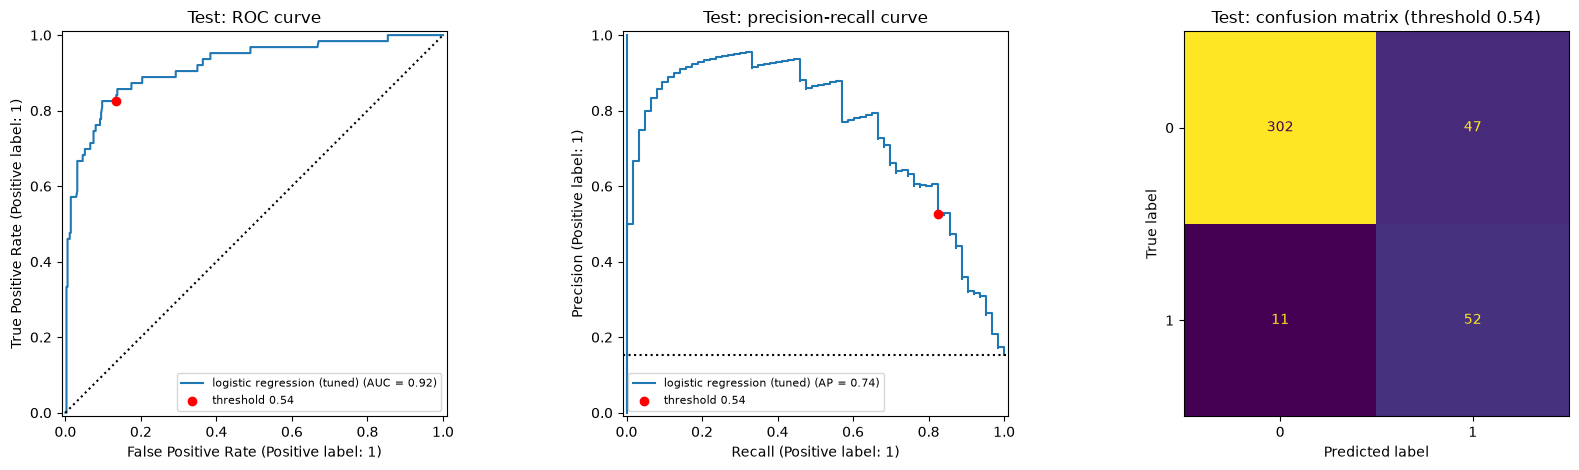

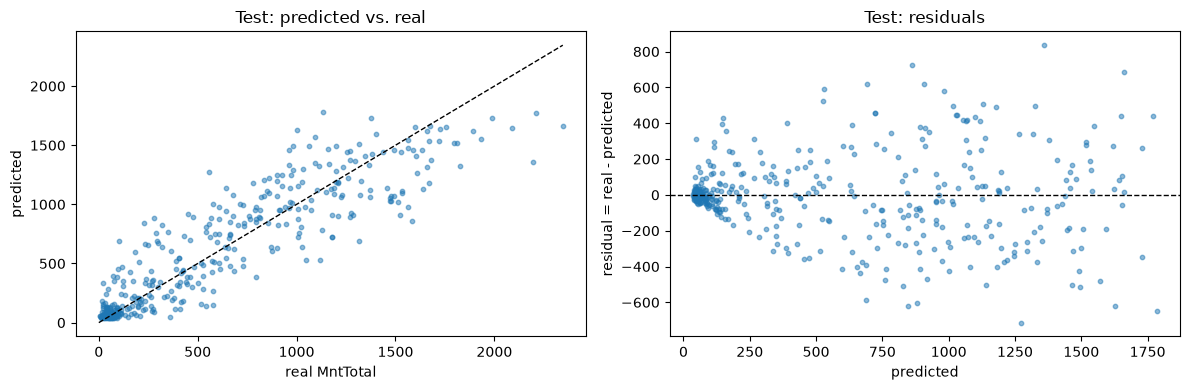

,MAE,mean residual
MntTotal,,
Q1 (low),38.3,-32.2
Q2,137.5,-64.0
Q3,195.8,-69.1
Q4 (high),268.6,143.1


In [32]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
RocCurveDisplay.from_predictions(yc_test, p_te, name=FINAL_C, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k:")
fpr_t = ((p_te >= THRESHOLD) & (yc_test == 0)).sum() / (yc_test == 0).sum()
axes[0].scatter(fpr_t, test_c["recall"], color="red", zorder=3, label=f"threshold {THRESHOLD:.2f}")
axes[0].set_title("Test: ROC curve")
PrecisionRecallDisplay.from_predictions(yc_test, p_te, name=FINAL_C, ax=axes[1])
axes[1].scatter(test_c["recall"], test_c["precision"], color="red", zorder=3, label=f"threshold {THRESHOLD:.2f}")
axes[1].axhline(yc_test.mean(), color="k", linestyle=":")
axes[1].set_title("Test: precision-recall curve")
for ax in axes[:2]:
    ax.legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(yc_test, pred_c, ax=axes[2], colorbar=False)
axes[2].set_title(f"Test: confusion matrix (threshold {THRESHOLD:.2f})")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_08_test_classification.png", dpi=150, bbox_inches="tight")
plt.show()

resid = yr_test - pred_r
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(yr_test, pred_r, s=10, alpha=0.5)
axes[0].plot([0, yr_test.max()], [0, yr_test.max()], "k--", linewidth=1)
axes[0].set(xlabel=f"real {TARGET_REG}", ylabel="predicted", title="Test: predicted vs. real")
axes[1].scatter(pred_r, resid, s=10, alpha=0.5)
axes[1].axhline(0, color="k", linestyle="--", linewidth=1)
axes[1].set(xlabel="predicted", ylabel="residual = real - predicted", title="Test: residuals")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_09_test_regression.png", dpi=150, bbox_inches="tight")
plt.show()

quart = pd.qcut(yr_test, 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
display(pd.DataFrame({"MAE": resid.abs(), "mean residual": resid}).groupby(quart, observed=True).mean().round(1))

### 11.1 Ce atribute folosesc modelele? (importanța prin permutare, pe test)

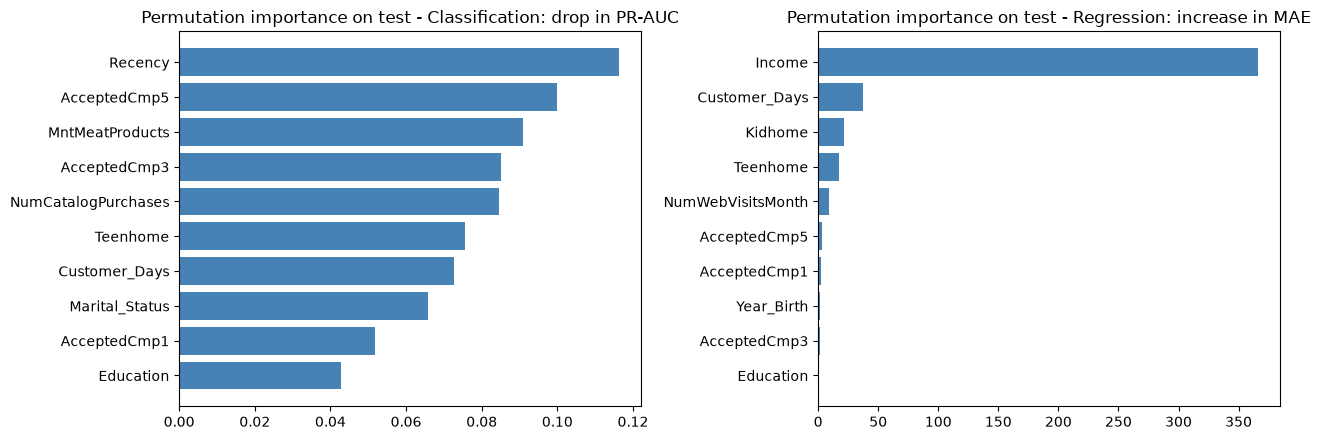

In [33]:
from sklearn.inspection import permutation_importance

imp_c = permutation_importance(final_c, Xc_test, yc_test, scoring="average_precision", n_repeats=20, random_state=SEED, n_jobs=-1)
imp_r = permutation_importance(final_r, Xr_test, yr_test, scoring="neg_mean_absolute_error", n_repeats=20, random_state=SEED, n_jobs=-1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, imp, X, title in [(axes[0], imp_c, Xc_test, "Classification: drop in PR-AUC"),
                          (axes[1], imp_r, Xr_test, "Regression: increase in MAE")]:
    top = pd.Series(imp.importances_mean, index=X.columns).sort_values().tail(10)
    ax.barh(top.index, top.values, color="steelblue")
    ax.set(title=f"Permutation importance on test - {title}")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_10_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### 11.2 Contribuție: pragul ales după profit

,contacted (train),"profit per customer (train, OOF)",profit per customer (test)
strategy,,,
contact everyone,1.000,-1.329,-1.318
threshold max F1 (0.53),0.258,0.517,0.684
threshold recall>=0.75 (0.54),0.254,0.515,0.667
threshold max profit (0.53),0.258,0.517,0.684


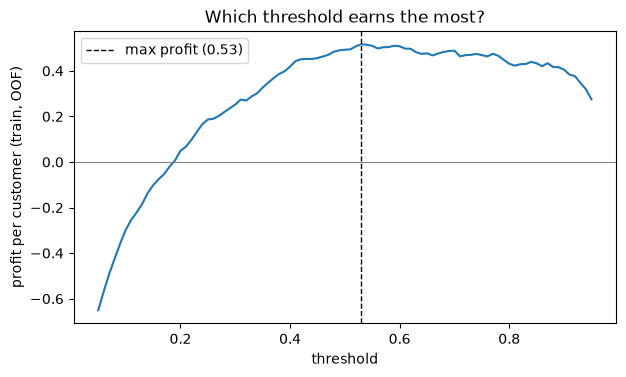

In [34]:
REVENUE, COST = 11, 3


def profit(y_true, contacted):
    y_true, contacted = np.asarray(y_true).astype(bool), np.asarray(contacted).astype(bool)
    return REVENUE * (y_true & contacted).sum() - COST * contacted.sum()


profits = [profit(yc_train, p_oof >= t) for t in thresholds]
T_PROFIT = thresholds[int(np.argmax(profits))]
T_F1 = thresholds[int(np.argmax([f1_score(yc_train, p_oof >= t) for t in thresholds]))]

rows = []
for name, c_tr, c_te in [("contact everyone", np.ones(len(yc_train)), np.ones(len(yc_test))),
                         (f"threshold max F1 ({T_F1:.2f})", p_oof >= T_F1, p_te >= T_F1),
                         (f"threshold recall>=0.75 ({THRESHOLD:.2f})", p_oof >= THRESHOLD, p_te >= THRESHOLD),
                         (f"threshold max profit ({T_PROFIT:.2f})", p_oof >= T_PROFIT, p_te >= T_PROFIT)]:
    rows.append({"strategy": name, "contacted (train)": np.mean(c_tr),
                 "profit per customer (train, OOF)": profit(yc_train, c_tr) / len(yc_train),
                 "profit per customer (test)": profit(yc_test, c_te) / len(yc_test)})
display(pd.DataFrame(rows).set_index("strategy").round(3))

plt.figure(figsize=(7, 3.8))
plt.plot(thresholds, np.array(profits) / len(yc_train))
plt.axvline(T_PROFIT, color="k", linestyle="--", linewidth=1, label=f"max profit ({T_PROFIT:.2f})")
plt.axhline(0, color="gray", linewidth=0.8)
plt.gca().set(xlabel="threshold", ylabel="profit per customer (train, OOF)", title="Which threshold earns the most?")
plt.legend()
plt.savefig(f"{FIGURES_DIR}/{MY_NAME}_11_profit_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Concluzii